# DS Average Time Drift Analysis across 2022 Runs

This notebook analyzes the **$t_0^{\mathrm{DS}}$ distribution** (`reft-DS` histogram) across all available 2022 runs in `/eos/user/i/idioniso/Timing/`.

### Objectives:
1. Superimpose the $t_0^{\mathrm{DS}}$ distributions for all available runs in a single figure with color encoding by run number.
2. Characterize the LHC bunch timing structure and monitor clock phase drifts across runs.
3. Quantify the fraction of accepted muon events for different selection windows (static vs. dynamic mode).


In [1]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import uproot
import ddfUtils.mpl_styling as dms

# Prevent JupyROOT RCanvas crash in notebook environments
try:
    import ROOT
    ROOT.gROOT.SetBatch(True)
    import ROOT._jupyroot.helpers.utils as jutils
    jutils.RCanvasAvailable = lambda: False
except Exception:
    pass

# Set default font and style
plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "figure.titlesize": 16,
})
print("Environment and libraries initialized successfully.")


Environment and libraries initialized successfully.


In [2]:
timing_dir = "/eos/user/i/idioniso/Timing"
run_dirs = sorted(glob.glob(os.path.join(timing_dir, "run*")))

runs_data = []

for rd in run_dirs:
    bname = os.path.basename(rd)
    try:
        rnum = int(bname.replace("run00", "").replace("run0", "").replace("run", ""))
    except ValueError:
        continue

    # Preference: timewalk_calibration.root, fallback to merged_raw_histograms.root
    fpath = os.path.join(rd, "timewalk_calibration.root")
    if not os.path.exists(fpath):
        fpath = os.path.join(rd, "merged_raw_histograms.root")
    if not os.path.exists(fpath):
        continue

    try:
        with uproot.open(fpath) as f:
            if "reft-DS" not in f:
                continue
            counts, edges = f["reft-DS"].to_numpy()
            total = counts.sum()
            if total < 50:
                continue

            centers = 0.5 * (edges[:-1] + edges[1:])
            mode_idx = np.argmax(counts)
            mode_t = centers[mode_idx]
            peak_val = counts[mode_idx]

            # Peak-normalized (for clear comparison of shapes irrespective of run size)
            norm_peak = counts / peak_val
            # Area-normalized (unit density)
            norm_area = counts / total

            runs_data.append({
                "run": rnum,
                "path": fpath,
                "edges": edges,
                "centers": centers,
                "counts": counts,
                "norm_peak": norm_peak,
                "norm_area": norm_area,
                "total": total,
                "mode_t": mode_t,
                "peak_val": peak_val,
                "mode_err": 0.5 * (edges[1] - edges[0]),
            })
    except Exception as err:
        print(f"Skipping {bname} due to error: {err}")

runs_data.sort(key=lambda d: d["run"])
print(f"Successfully loaded reft-DS histograms for {len(runs_data)} runs.")
if runs_data:
    r_first = runs_data[0]["run"]
    r_last = runs_data[-1]["run"]
    print(f"Run range: {r_first} -> {r_last}")


Successfully loaded reft-DS histograms for 50 runs.
Run range: 4427 -> 4813


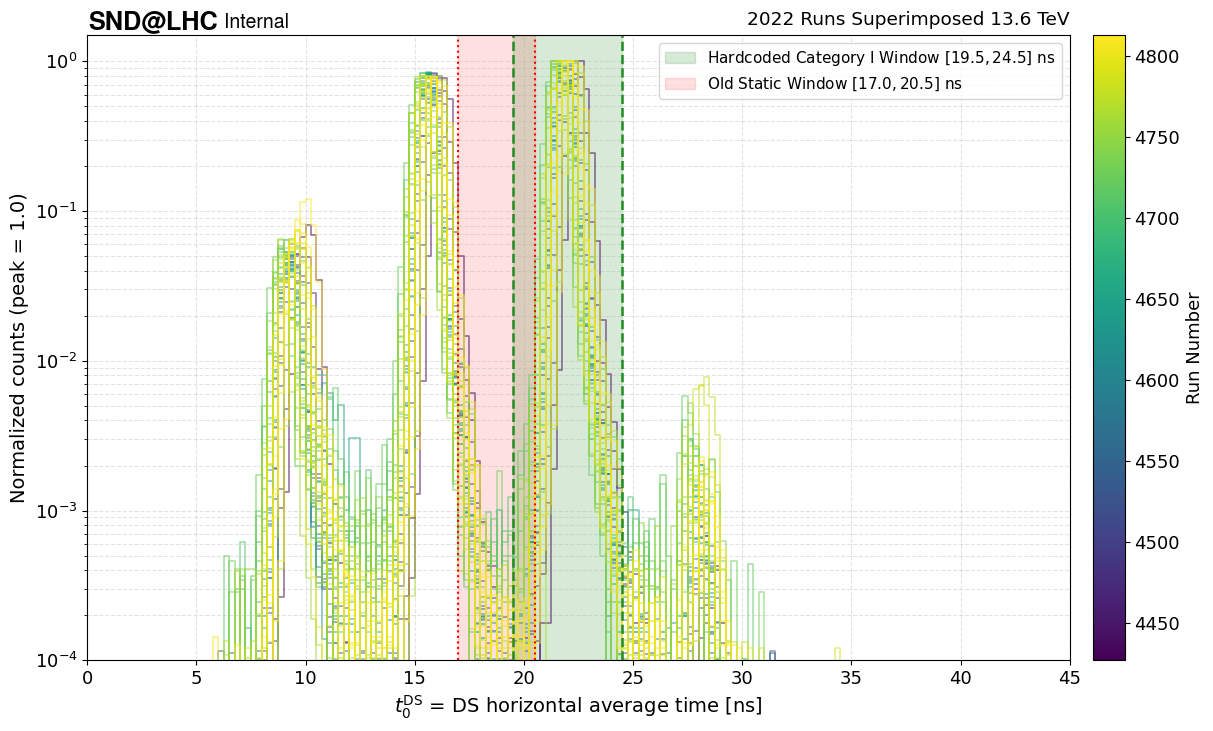

In [3]:
fig, ax = plt.subplots(figsize=(13, 7.5))

run_numbers = [d["run"] for d in runs_data]
min_run, max_run = min(run_numbers), max(run_numbers)
norm = mcolors.Normalize(vmin=min_run, vmax=max_run)
cmap = cm.viridis

# Plot each run with color mapped to run number
for d in runs_data:
    color = cmap(norm(d["run"]))
    ax.step(d["edges"][:-1], d["norm_peak"], where="post", color=color, alpha=0.55, lw=1.2)

# Shaded window: Hardcoded Category I window [19.5, 24.5] ns
ax.axvspan(19.5, 24.5, color="forestgreen", alpha=0.18, label=r"Hardcoded Category I Window $[19.5, 24.5]$ ns")
ax.axvline(19.5, color="forestgreen", linestyle="--", lw=1.8)
ax.axvline(24.5, color="forestgreen", linestyle="--", lw=1.8)

# Old static window [17.0, 20.5] for comparison
ax.axvspan(17.0, 20.5, color="red", alpha=0.12, label=r"Old Static Window $[17.0, 20.5]$ ns")
ax.axvline(17.0, color="red", linestyle=":", lw=1.5)
ax.axvline(20.5, color="red", linestyle=":", lw=1.5)

ax.set_yscale("log")
ax.set_ylim(1e-4, 1.5)
ax.set_xlim(0, 45)
ax.set_xlabel(r"$t_0^{\mathrm{DS}}$ = DS horizontal average time [ns]", fontsize=14)
ax.set_ylabel("Normalized counts (peak = 1.0)", fontsize=14)
ax.grid(True, which="both", linestyle="--", alpha=0.35)

# Add colorbar
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("Run Number", fontsize=13)

# Add experiment label
dms.add_label(mainText="SND@LHC", extraText="Internal", suppText="2022 Runs Superimposed", ax=ax)

ax.legend(loc="upper right", frameon=True, fontsize=11)
plt.tight_layout()
plt.show()

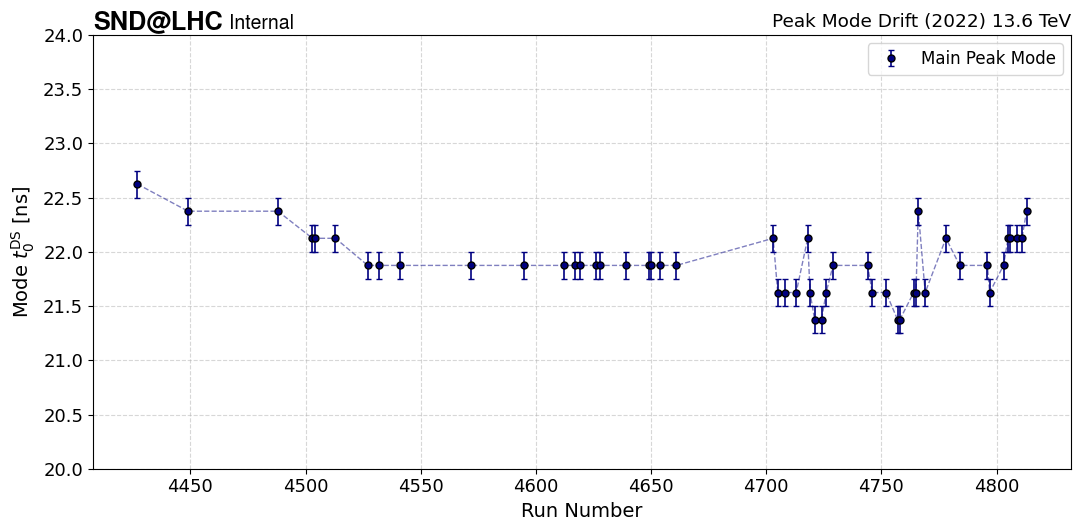

In [4]:
fig, ax = plt.subplots(figsize=(11, 5.5))

runs = [d["run"] for d in runs_data]
modes = [d["mode_t"] for d in runs_data]
mode_errs = [d.get("mode_err", 0.5 * (d["edges"][1] - d["edges"][0])) for d in runs_data]

ax.errorbar(runs, modes, yerr=mode_errs, fmt="o", color="navy", ecolor="navy",
            elinewidth=1.2, capsize=2.5, markersize=5, markeredgecolor="black",
            zorder=3, label="Main Peak Mode")
ax.plot(runs, modes, color="navy", linestyle="--", alpha=0.5, lw=1)

ax.set_xlabel("Run Number", fontsize=14)
ax.set_ylabel(r"Mode $t_0^{\mathrm{DS}}$ [ns]", fontsize=14)
ax.set_ylim(20.0, 24.0)
ax.grid(True, linestyle="--", alpha=0.5)

# Add experiment label
dms.add_label(mainText="SND@LHC", extraText="Internal", suppText="Peak Mode Drift (2022)", ax=ax)

ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

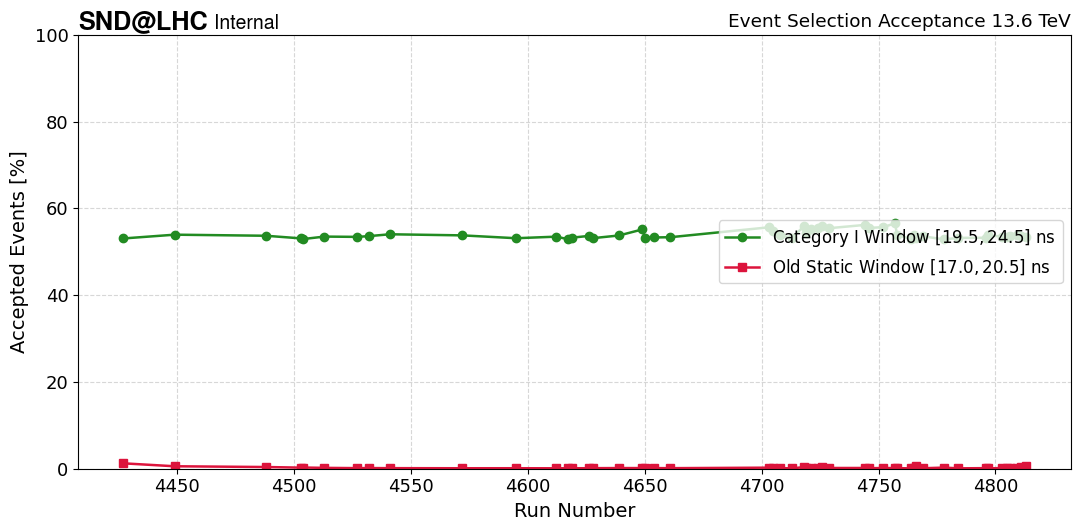

Mean acceptance with [19.5, 24.5] window: 54.0% (min: 52.9%, max: 56.6%)
Mean acceptance with Old [17.0, 20.5] window: 0.2% (min: 0.1%, max: 1.2%)


In [5]:
# Compare event acceptance for hardcoded Category I window [19.5, 24.5] vs old [17.0, 20.5]
def get_acceptance(d, t_min, t_max):
    mask = (d["centers"] >= t_min) & (d["centers"] <= t_max)
    return 100.0 * d["counts"][mask].sum() / d["total"]

acc_hardcoded = [get_acceptance(d, 19.5, 24.5) for d in runs_data]
acc_old_static = [get_acceptance(d, 17.0, 20.5) for d in runs_data]

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(runs, acc_hardcoded, marker="o", color="forestgreen", lw=1.8, label=r"Category I Window $[19.5, 24.5]$ ns")
ax.plot(runs, acc_old_static, marker="s", color="crimson", lw=1.8, label=r"Old Static Window $[17.0, 20.5]$ ns")

ax.set_xlabel("Run Number", fontsize=14)
ax.set_ylabel("Accepted Events [%]", fontsize=14)
ax.set_ylim(0, 100)
ax.grid(True, linestyle="--", alpha=0.5)

dms.add_label(mainText="SND@LHC", extraText="Internal", suppText="Event Selection Acceptance", ax=ax)

ax.legend(loc="center right", frameon=True)
plt.tight_layout()
plt.show()

mean_hc = np.mean(acc_hardcoded)
min_hc, max_hc = np.min(acc_hardcoded), np.max(acc_hardcoded)
mean_old = np.mean(acc_old_static)
min_old, max_old = np.min(acc_old_static), np.max(acc_old_static)

print(f"Mean acceptance with [19.5, 24.5] window: {mean_hc:.1f}% (min: {min_hc:.1f}%, max: {max_hc:.1f}%)")
print(f"Mean acceptance with Old [17.0, 20.5] window: {mean_old:.1f}% (min: {min_old:.1f}%, max: {max_old:.1f}%)")
